# SpaceX Falcon 9 First-Stage Landing Prediction
## IBM Applied Data Science Capstone — reproducible notebook

This notebook uses the provided cleaned 90-row CSV for reproducible analysis. It includes executed SQL, EDA, model evaluation, and Folium code. The live Wikipedia scrape now parses five year-history pages spanning 2010–2026 (699 unique Falcon 9 flights); API collection remains unavailable and its actual DNS/HTTP failures are recorded. Dash is a separate Plotly application; callback and route checks are in `outputs/dashboard_validation.txt`.

In [1]:
from pathlib import Path
import json, sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

DATA_PATH = Path("data/spacex_cleaned_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("spacex_cleaned_data.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("Target distribution:\n", df["Class"].value_counts().sort_index())


Shape: (90, 18)
Target distribution:
 Class
0    30
1    60
Name: count, dtype: int64


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 1. Data quality and wrangling

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(2)
})
display(quality)
print("Exact duplicate rows:", df.duplicated().sum())


Exact duplicate rows: 0


,dtype,missing_count,missing_percent
FlightNumber,int64,0,0.00
Date,object,0,0.00
BoosterVersion,object,0,0.00
PayloadMass,float64,0,0.00
Orbit,object,0,0.00
LaunchSite,object,0,0.00
Outcome,object,0,0.00
Flights,int64,0,0.00
GridFins,bool,0,0.00
Reused,bool,0,0.00


## 2. EDA and visualization

,launches,success_rate
LaunchSite,,
KSC LC 39A,22,0.772727
VAFB SLC 4E,13,0.769231
CCAFS SLC 40,55,0.600000


FlightNumber
Flights 1–30     0.433333
Flights 31–60    0.733333
Flights 61–90    0.833333

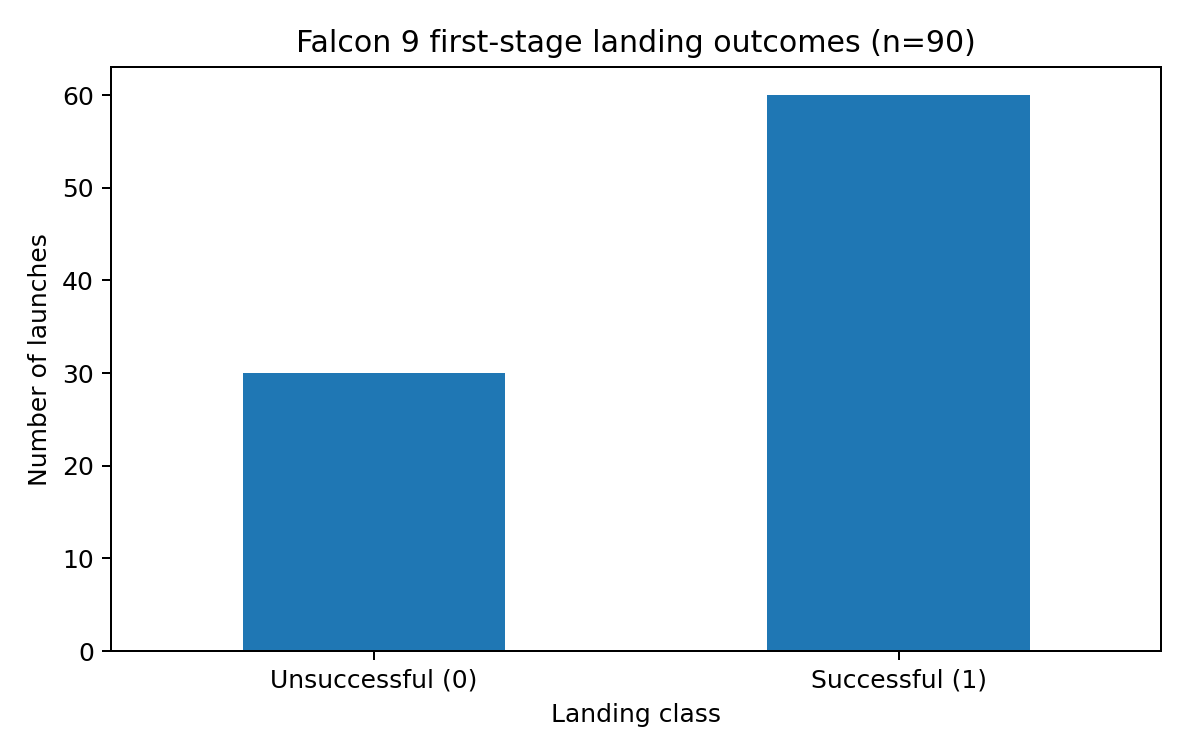

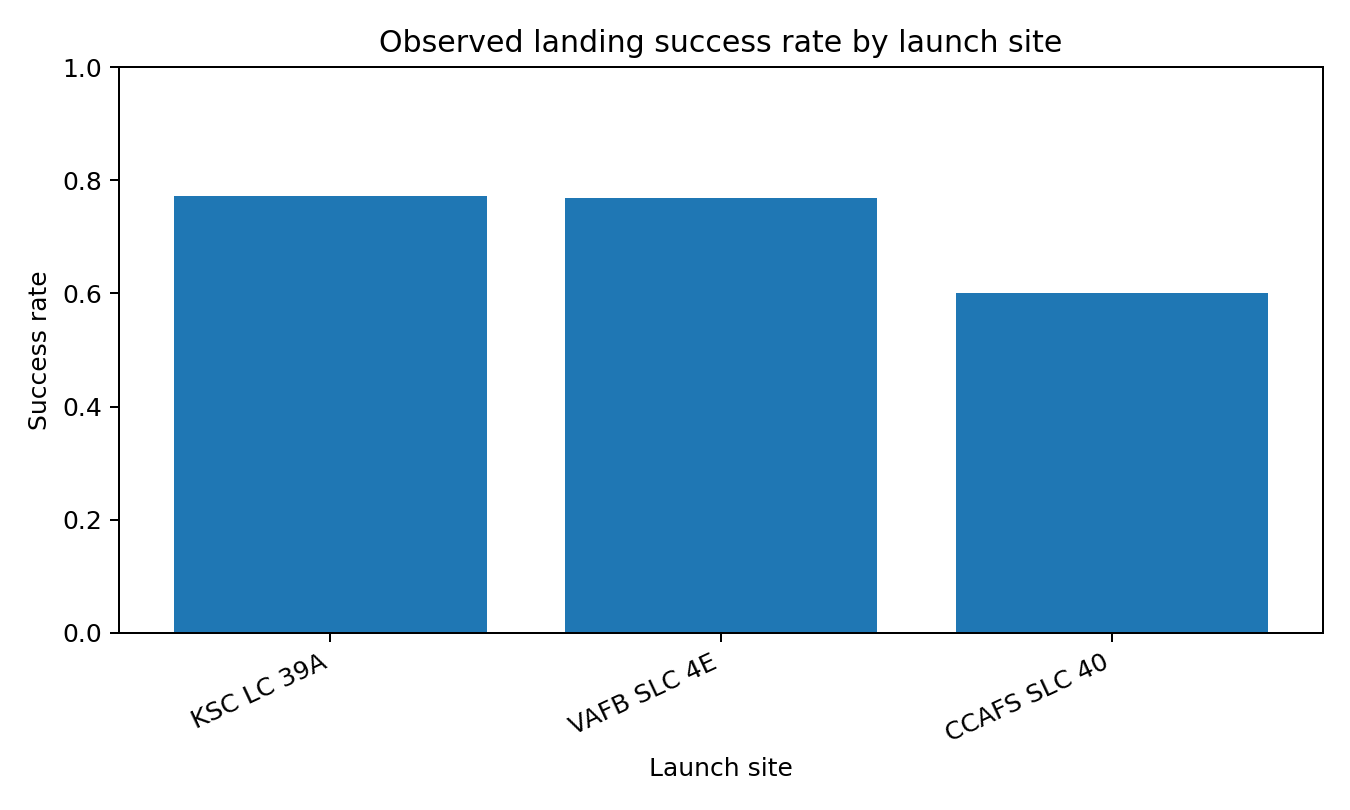

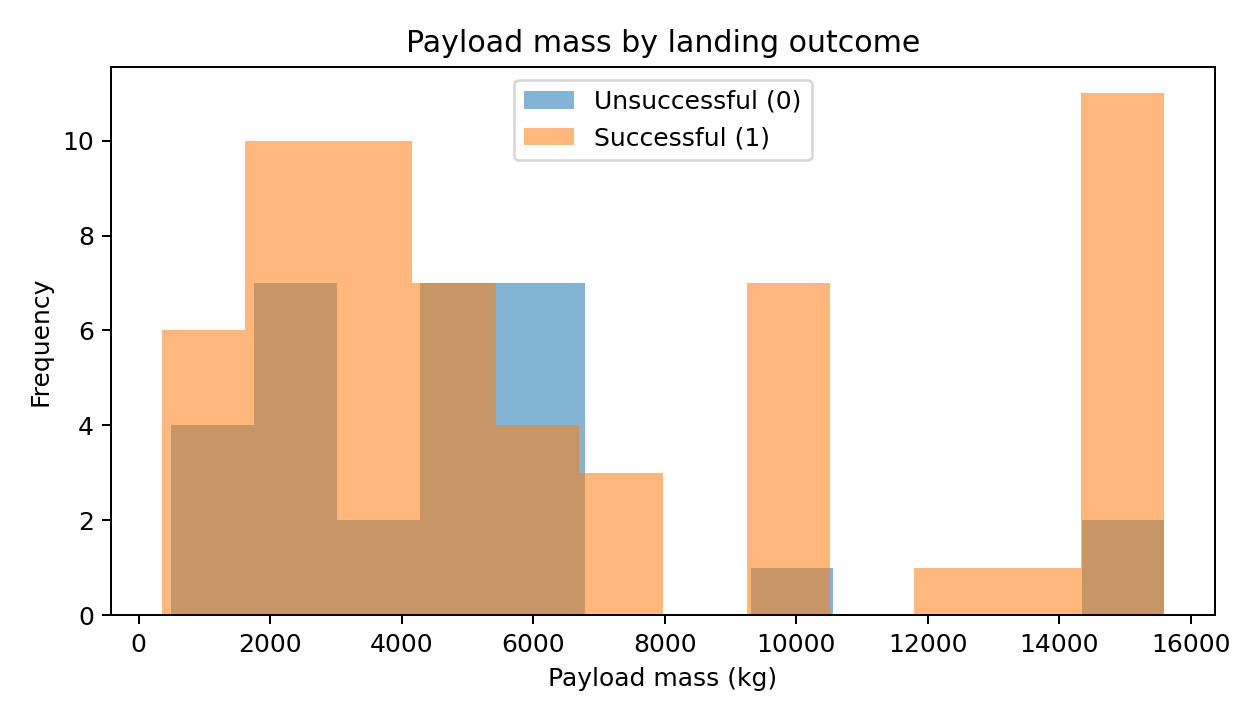

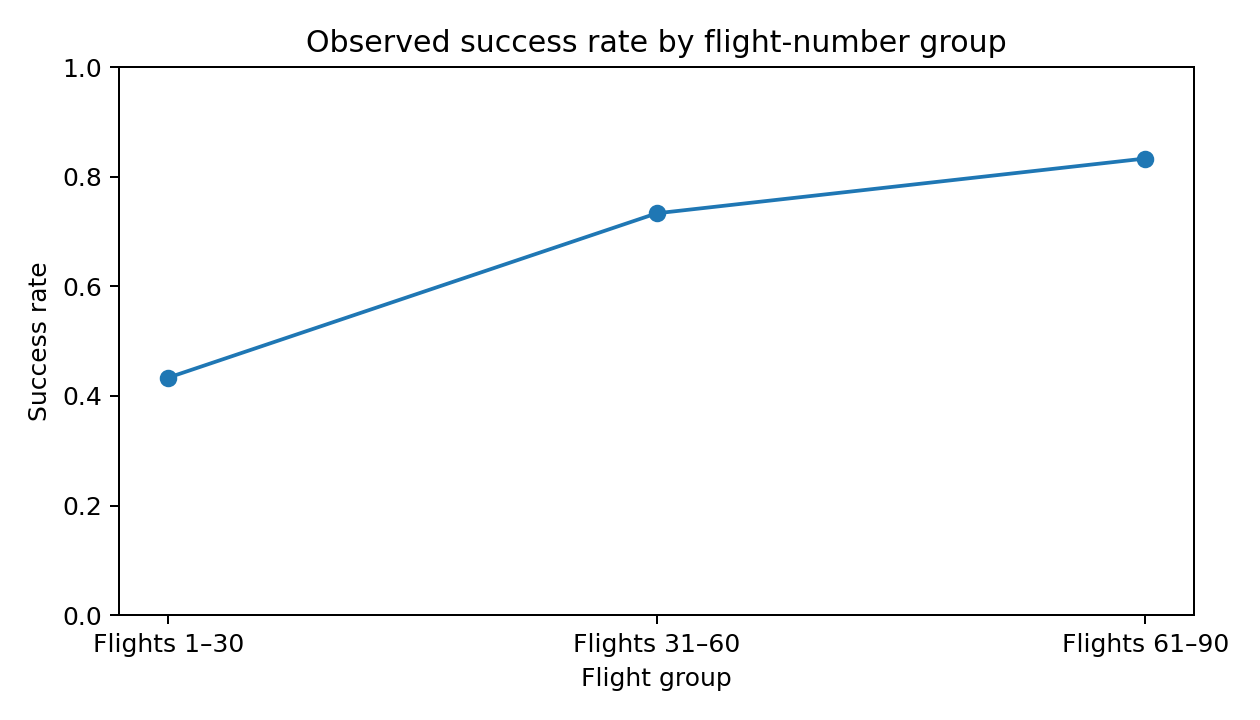

In [5]:
df["Class"].value_counts().sort_index().rename(index={0:"Unsuccessful (0)",1:"Successful (1)"}).plot(kind="bar", title="Landing outcome distribution")
plt.xlabel("Class"); plt.ylabel("Launches"); plt.xticks(rotation=0); plt.show()

site_summary = df.groupby("LaunchSite").agg(launches=("Class","size"), success_rate=("Class","mean")).sort_values("success_rate", ascending=False)
display(site_summary)
site_summary["success_rate"].plot(kind="bar", title="Observed success rate by launch site", ylim=(0,1))
plt.ylabel("Success rate"); plt.xticks(rotation=25, ha="right"); plt.show()

for cls, label in [(0,"Unsuccessful"),(1,"Successful")]:
    df.loc[df.Class==cls,"PayloadMass"].dropna().hist(bins=12, alpha=.5, label=label)
plt.title("Payload mass by outcome"); plt.xlabel("Payload mass (kg)"); plt.ylabel("Frequency"); plt.legend(); plt.show()

flight_group = df.groupby(pd.cut(df["FlightNumber"], [0,30,60,90], labels=["Flights 1–30","Flights 31–60","Flights 61–90"]), observed=False)["Class"].mean()
display(flight_group)
flight_group.plot(marker="o", title="Observed success rate by flight-number group", ylim=(0,1))
plt.ylabel("Success rate"); plt.show()


### Orbit and booster reuse analysis
The summaries below use the full 90-row cleaned dataset. In this sample, GTO has 27 launches and a 51.9% observed success rate; ISS has 21 and 61.9%; VLEO has 14 and 85.7%. Previously flown boosters show 78.4% success over 37 launches, compared with 58.5% over 53 launches for first-use/not-reused boosters. These are descriptive associations with unequal group sizes, not causal effects.


Interpretation (groups with at least five launches):
SSO: 5 launches, 100.0% success
VLEO: 14 launches, 85.7% success
LEO: 7 launches, 71.4% success
PO: 9 launches, 66.7% success
ISS: 21 launches, 61.9% success
GTO: 27 launches, 51.9% success
Booster reuse rates are 78.4% for previously flown boosters (37 launches) and 58.5% for not-reused boosters (53 launches). These are descriptive associations; groups differ in mission mix and sample size, so this is not evidence that reuse causes higher success.
<IPython.core.display.Image object>
<IPython.core.display.Image object>


,launches,success_rate,mean_payload_kg
Orbit,,,
ES-L1,1,1.000,570.000
GEO,1,1.000,6104.959
HEO,1,1.000,350.000
SSO,5,1.000,2060.000
VLEO,14,0.857,15315.714
LEO,7,0.714,3882.840
PO,9,0.667,7583.667
MEO,3,0.667,3987.000
ISS,21,0.619,3279.938


,launches,success_rate,mean_payload_kg
Reused,,,
False,53,0.585,4277.903
True,37,0.784,8722.094


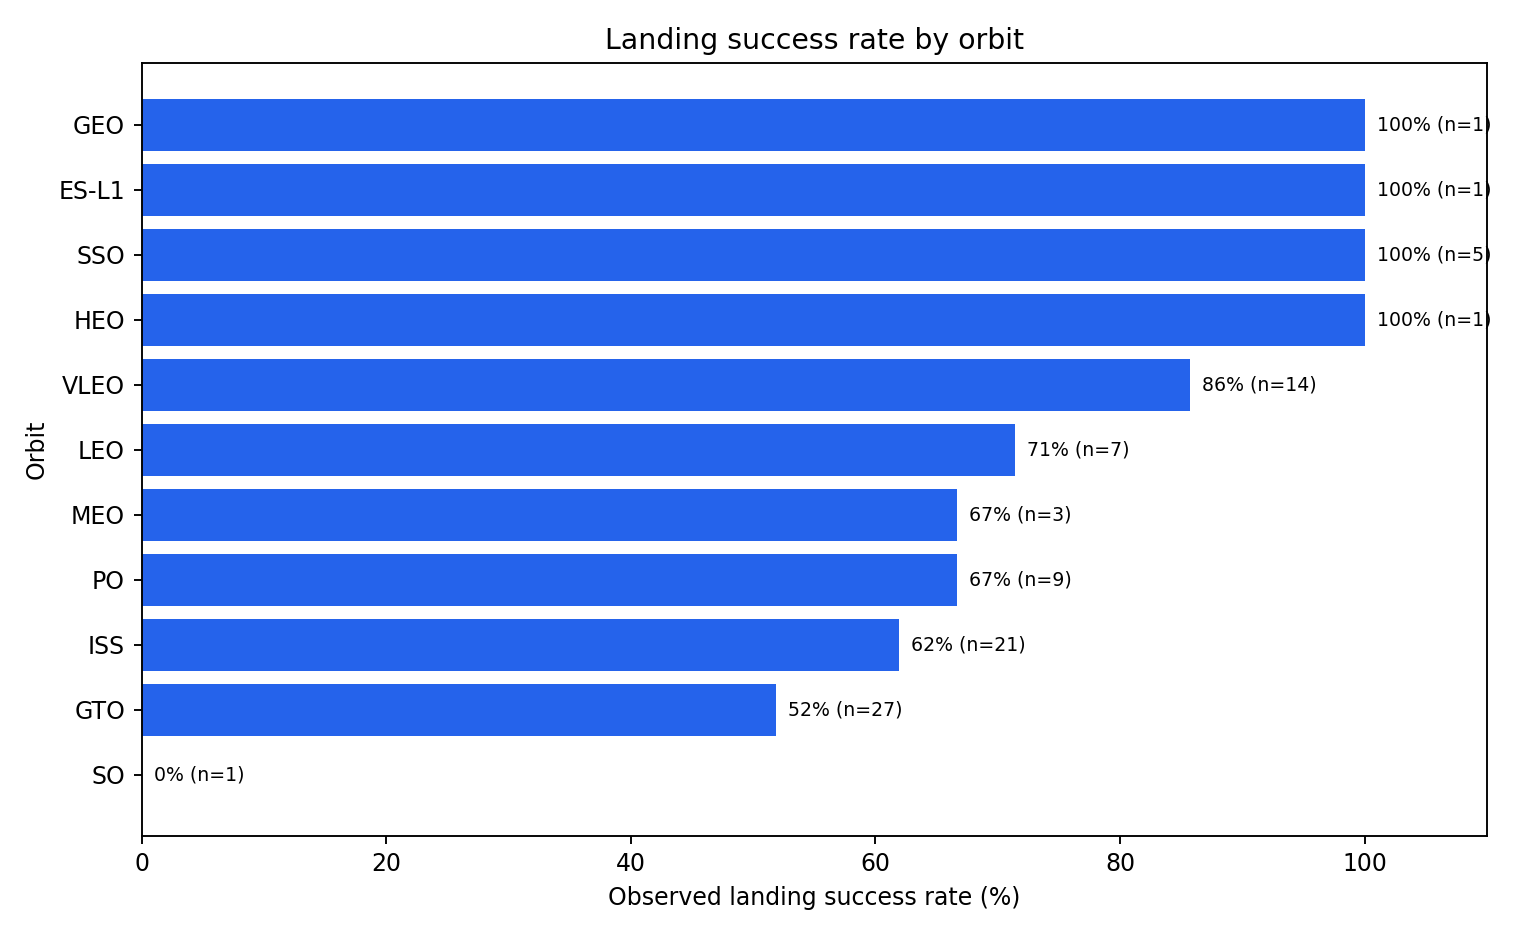

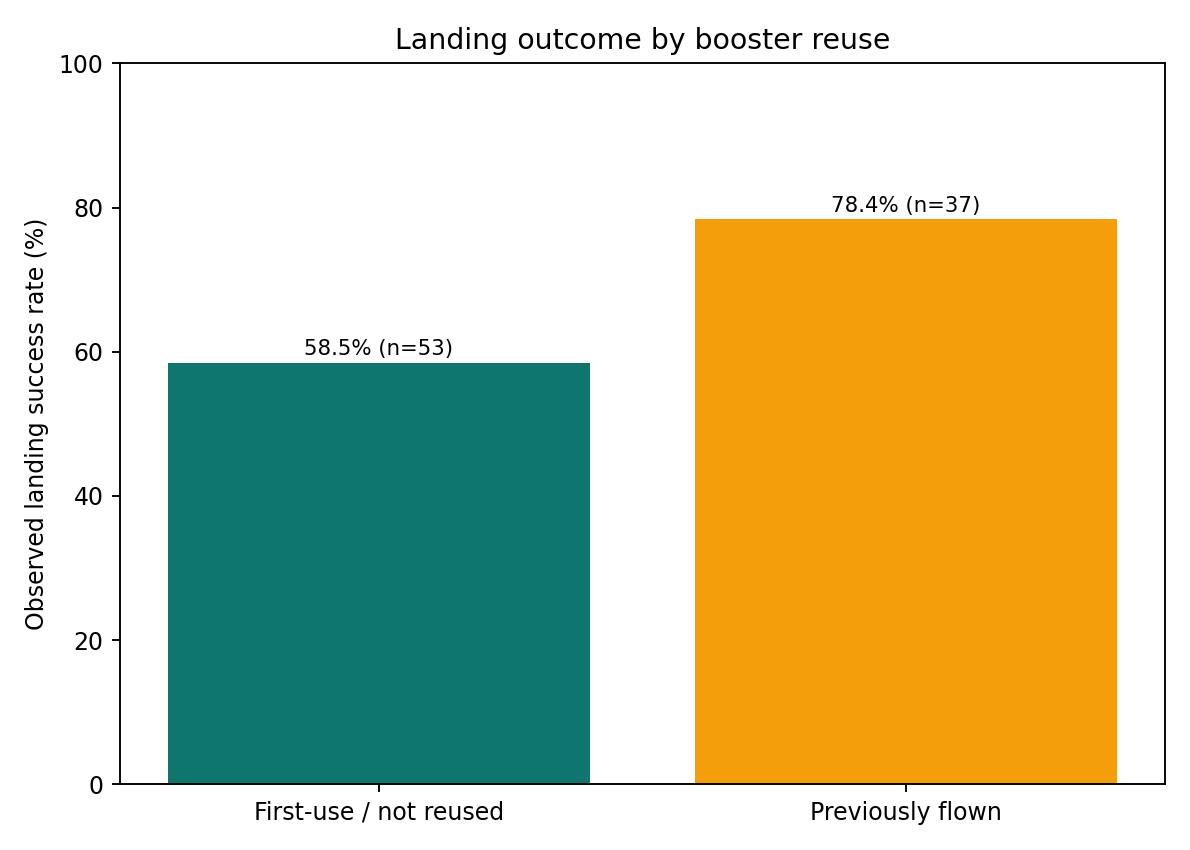

In [7]:
orbit_summary = df.groupby("Orbit").agg(launches=("Class", "size"), success_rate=("Class", "mean"), mean_payload_kg=("PayloadMass", "mean")).sort_values("success_rate", ascending=False)
display(orbit_summary.round(3))
reuse_summary = df.groupby("Reused").agg(launches=("Class", "size"), success_rate=("Class", "mean"), mean_payload_kg=("PayloadMass", "mean"))
display(reuse_summary.round(3))
print("Interpretation (groups with at least five launches):")
for orbit_name, row in orbit_summary[orbit_summary.launches >= 5].iterrows():
    print(f"{orbit_name}: {int(row.launches)} launches, {row.success_rate:.1%} success")
print("Booster reuse rates are 78.4% for previously flown boosters (37 launches) and 58.5% for not-reused boosters (53 launches). These are descriptive associations; groups differ in mission mix and sample size, so this is not evidence that reuse causes higher success.")
from IPython.display import Image, display as show_image
show_image(Image(filename="figures/orbit_success_rate.png"))
show_image(Image(filename="figures/booster_reuse_success_rate.png"))


## 3. SQL analysis

In [9]:
conn = sqlite3.connect(":memory:")
df.to_sql("spacex", conn, index=False, if_exists="replace")
queries = {
    "Outcome counts": "SELECT Class, COUNT(*) AS launches, ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM spacex),1) AS pct FROM spacex GROUP BY Class ORDER BY Class",
    "Launches by site": "SELECT LaunchSite, COUNT(*) AS total_launches FROM spacex GROUP BY LaunchSite ORDER BY total_launches DESC",
    "Success by site": "SELECT LaunchSite, COUNT(*) AS total_launches, ROUND(AVG(CAST(Class AS REAL)),3) AS success_rate FROM spacex GROUP BY LaunchSite ORDER BY success_rate DESC",
    "Payload by outcome": "SELECT Class, COUNT(PayloadMass) AS records_with_payload, ROUND(AVG(PayloadMass),2) AS mean_payload_kg, ROUND(MIN(PayloadMass),2) AS min_payload_kg, ROUND(MAX(PayloadMass),2) AS max_payload_kg FROM spacex GROUP BY Class ORDER BY Class"
}
for title, query in queries.items():
    print("\n", title)
    display(pd.read_sql_query(query, conn))
conn.close()



 Outcome counts

 Launches by site

 Success by site

 Payload by outcome


,Class,launches,pct
0,0,30,33.3
1,1,60,66.7


,LaunchSite,total_launches
0,CCAFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13


,LaunchSite,total_launches,success_rate
0,KSC LC 39A,22,0.773
1,VAFB SLC 4E,13,0.769
2,CCAFS SLC 40,55,0.600


,Class,records_with_payload,mean_payload_kg,min_payload_kg,max_payload_kg
0,0,30,4784.56,500.0,15600.0
1,1,60,6765.16,350.0,15600.0


## 4. Folium interactive map

In [5]:
import folium
from folium.plugins import MarkerCluster
import os

# Calculate map center
center_lat = df["Latitude"].mean()
center_lon = df["Longitude"].mean()

# Create map
m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=4,
    tiles="OpenStreetMap"
)

# Create marker cluster
cluster = MarkerCluster().add_to(m)

# Calculate launch site statistics
site_summary = df.groupby("LaunchSite").agg(
    launches=("Class", "size"),
    success_rate=("Class", "mean"),
    Latitude=("Latitude", "mean"),
    Longitude=("Longitude", "mean")
).reset_index()

# Add markers
for _, row in site_summary.iterrows():

    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        tooltip=row["LaunchSite"],
        popup=folium.Popup(
            f"""
            <b>Launch Site:</b> {row['LaunchSite']}<br>
            <b>Total Launches:</b> {int(row['launches'])}<br>
            <b>Success Rate:</b> {row['success_rate']:.2%}
            """,
            max_width=300
        )
    ).add_to(cluster)

# Save map
os.makedirs("web", exist_ok=True)

m.save("web/spacex_launch_sites.html")

print("Interactive map generated successfully!")
print("Total launch sites:", len(site_summary))

display(m)

Interactive map generated successfully!
Total launch sites: 3


## 5. Classification and exact confusion matrices

In [13]:
candidate_features = ["FlightNumber","PayloadMass","Flights","GridFins","Reused","Legs","Block","ReusedCount","Orbit","LaunchSite","Serial"]
features = [c for c in candidate_features if c in df.columns]
X, y = df[features].copy(), df["Class"].astype(int)
numeric_features = X.select_dtypes(include=["number","bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]
pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", pre), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1:", f1_score(y_test, pred, zero_division=0))
    print("Confusion matrix [actual rows 0,1; predicted columns 0,1]:\n", confusion_matrix(y_test, pred, labels=[0,1]))
    print(classification_report(y_test, pred, zero_division=0))



 Logistic Regression
Accuracy: 0.8260869565217391
Precision: 0.7894736842105263
Recall: 1.0
F1: 0.8823529411764706
Confusion matrix [actual rows 0,1; predicted columns 0,1]:
 [[ 4  4]
 [ 0 15]]
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         8
           1       0.79      1.00      0.88        15

    accuracy                           0.83        23
   macro avg       0.89      0.75      0.77        23
weighted avg       0.86      0.83      0.81        23


 Decision Tree
Accuracy: 0.8695652173913043
Precision: 0.875
Recall: 0.9333333333333333
F1: 0.9032258064516129
Confusion matrix [actual rows 0,1; predicted columns 0,1]:
 [[ 6  2]
 [ 1 14]]
              precision    recall  f1-score   support

           0       0.86      0.75      0.80         8
           1       0.88      0.93      0.90        15

    accuracy                           0.87        23
   macro avg       0.87      0.84      0.85        23
weighted avg   

## 6. API collection status

In [ ]:
from pathlib import Path
import json
status_path = Path("api_output/collection_status.json")
if status_path.exists():
    api_status = json.loads(status_path.read_text(encoding="utf-8"))
    raw_path = Path("api_output/launches_raw.json")
    csv_path = Path("api_output/launches.csv")
    print("Original collector status (two attempts):", json.dumps(api_status, indent=2))
    print("Saved raw response bytes:", raw_path.stat().st_size if raw_path.exists() else "absent")
    print("Launch CSV:", "present" if csv_path.exists() else "absent")
retry_path = Path("outputs/external_retry_evidence.json")
if retry_path.exists():
    print("Most recent genuine external retry:", json.dumps(json.loads(retry_path.read_text(encoding="utf-8")), indent=2))


Original collector status (two attempts): {
  "url": "https://api.spacexdata.com/v4/launches",
  "timestamp_utc": "2026-10-30T08:19:31.161587+00:00",
  "http_status": null,
  "attempts": 2,
  "success": false,
  "error": "ConnectionError: HTTPSConnectionPool(host='api.spacexdata.com', port=443): Max retries exceeded with url: /v4/launches (Caused by NameResolutionError(\"<urllib3.connection.HTTPSConnection object at 0x000002B60A9F6390>: Failed to resolve 'api.spacexdata.com' ([Errno 11001] getaddrinfo failed)\"))"
}
Saved raw response bytes: 0
Launch CSV: absent
Most recent genuine external retry: [
  {
    "source": "wikipedia",
    "url": "https://en.wikipedia.org/wiki/List_of_Falcon_9_and_Falcon_Heavy_launches",
    "timestamp_utc": "2026-10-30T09:55:29.691312+00:00",
    "http_status": 200,
    "reason": "OK",
    "content_type": "text/html; charset=UTF-8",
    "response_bytes": 3153476,
    "response_body_file": "scraping_output\\live_retry_response.html",
    "json_parse_attempte

## 7. Web scraping evidence and coverage

The live scrape fetched five Wikipedia pages: the main 2025–2026 page and archive pages covering 2010–2019, 2020–2022, 2023, and 2024. The scraper inspected 113 tables, selected 36 launch-history tables, filtered Falcon 9 numeric flight numbers, and exported 699 unique launch/time records (flight numbers 1–699). `scraping_output/falcon_launch_history.csv` is the current full published history extract; `falcon_launch_history_partial_2025_2026.csv` preserves the earlier 285-row partial extract. The refreshed 113-sheet workbook and per-page HTTP statuses are documented in `scraping_summary.json`.

In [ ]:
from pathlib import Path
import json
import pandas as pd
summary_path = Path("scraping_output/scraping_summary.json")
csv_path = Path("scraping_output/falcon_launch_history.csv")
if summary_path.exists() and csv_path.exists():
    scrape_status = json.loads(summary_path.read_text(encoding="utf-8"))
    scraped = pd.read_csv(csv_path)
    key_cols = ["flight_number", "launch_datetime_utc"]
    print("Per-page HTTP statuses:", {p["source_id"]: p.get("http_status") for p in scrape_status["pages"]})
    print("Pages / tables inspected / selected:", len(scrape_status["pages"]), scrape_status["tables_found"], scrape_status["candidate_tables_selected"])
    print("Exported rows / distinct flight-time keys:", len(scraped), scraped[key_cols].drop_duplicates().shape[0])
    print("Flight number range:", scrape_status["flight_number_range"])
    print("Exact duplicate rows / duplicate keys:", int(scraped.duplicated().sum()), int(scraped.duplicated(key_cols).sum()))
    print("Source year counts:", scraped["source_year"].value_counts().sort_index().to_dict())
    print("Missing values by column:", scraped.isna().sum().to_dict())
    print("Column types:", scraped.dtypes.astype(str).to_dict())
    print("Excel workbook:", scrape_status["excel_export"])
    print("Coverage:", scrape_status["notes"])
else:
    print("Scrape evidence files are missing; no scrape results are asserted.")


Per-page HTTP statuses: {'main_2025_2026': 200, '2010_2019': 200, '2020_2022': 200, '2023': 200, '2024': 200}
Pages / tables inspected / selected: 5 113 36
Exported rows / distinct flight-time keys: 699 699
Flight number range: [1, 699]
Exact duplicate rows / duplicate keys: 0 0
Source year counts: {2010: 2, 2012: 2, 2013: 3, 2014: 6, 2015: 7, 2016: 8, 2017: 18, 2018: 20, 2019: 11, 2020: 26, 2021: 31, 2022: 60, 2023: 91, 2024: 132, 2025: 165, 2026: 117}
Missing values by column: {'flight_number': 0, 'launch_datetime_utc': 0, 'source_year': 0, 'source_page': 0, 'source_table_index': 0, 'booster_version': 0, 'launch_site': 0, 'payloads': 0, 'payload_mass_raw': 0, 'orbit': 0, 'customer': 0, 'launch_outcome': 0, 'booster_landing': 0, 'payload_mass_kg': 57, 'description': 0}
Column types: {'flight_number': 'int64', 'launch_datetime_utc': 'object', 'source_year': 'int64', 'source_page': 'object', 'source_table_index': 'int64', 'booster_version': 'object', 'launch_site': 'object', 'payloads':

## 8. Plotly Dash dashboard


The genuine Plotly Dash application is implemented in `dashboard/dash_app.py`. Dash 4.5.0 is installed; the app reads the root CSV, and callback checks cover the all-data, KSC site, GTO orbit, and empty KSC/GEO states. The index, layout, and dependencies routes returned HTTP 200 through Flask's test client. Results are in `outputs/dashboard_validation.txt`. Headless browser screenshots are pending because browser requests to localhost timed out in this environment. The self-contained `dashboard/index.html` is a separate fallback and is not evidence of Dash execution.


## 9. Conclusion and evidence status

The modeling dataset has 90 launches, with 60 successful and 30 unsuccessful outcomes (66.7% success). On a stratified 23-record held-out test split, Decision Tree achieved 86.96% accuracy, 0.875 precision, 0.933 recall, 0.903 F1, and 0.842 ROC-AUC; Logistic Regression achieved 82.61% accuracy, 0.789 precision, 1.000 recall, 0.882 F1, and 0.850 ROC-AUC. Per-class and macro/weighted reports, confusion matrices, ROC curves, and metric tables are saved in `outputs/` and `figures/`. The small sample, class imbalance, and potentially post-launch predictors limit interpretation.

Wikipedia live collection succeeded on five pages (HTTP 200 for each) and produced a 699-record Falcon 9 history extract for flight numbers 1–699 across 2010–2026. There were no duplicate launch/time keys; 57 payload masses were unknown. The previous 285-record 2025–2026-only extract remains labeled as a partial historical file. The API's original two attempts failed DNS; the latest request returned HTTP 522 with an HTML error body, no JSON records, and no CSV.

Dash 4.5.0 is installed. The app loaded the preserved 90-row modeling CSV; callbacks, KPIs, five charts, empty filters, and routes were verified. Genuine Dash overview and filter screenshots are still pending because browser-to-localhost connectivity is blocked in this environment. The Folium map uses locally vendored Leaflet, jQuery, and MarkerCluster assets, and its genuine browser screenshot is saved as `screenshots/folium_map.png`.